# Repeat Jurnal Utama — Segmentasi 48 Sentra Wisata Kuliner (SWK) Surabaya

- **Judul Jurnal:** *Analisis Segmentasi Sentra Wisata Kuliner untuk Optimalisasi Omzet UMKM di Surabaya Menggunakan Metode Agglomerative Hierarchical Clustering*
- **Penulis:** Nabilah Selayanti, Shafira Amanda Putri, Tresna Maulana Fahrudin (UPN Veteran Jawa Timur)
- **Publikasi:** *Jurnal Multi Media dan IT (JoMMiT)*, Vol. 08 No. 02 (2024), hlm. 113–122 | DOI: `https://doi.org/10.46961/jommit.v8i2`
- **Dataset Asli:** Jumlah Sentra Wisata Kuliner Kota Surabaya — **lengkap 48 SWK × 11 variabel** (`kode11500kode25245kode3135.csv`, arsip resmi Satu Data Surabaya via Internet Archive Wayback Machine snapshot `22 Maret 2023`)
- **Keselarasan Diagram & Jurnal:** Urutan sel mengikuti **Draw.io Page 1–2** serta mereproduksi seluruh grafik (**Gambar 2, 3, 4, 5, 6, 7a, 8, & Grafik Silhouette `k=2..10`**) dan seluruh tabel (**Tabel 1, 2, 3, & 4 + daftar lengkap 48 SWK**) persis seperti jurnal.
- **Mahasiswa:** Muhammad Iqbal Rizanta (`09040624091`)

In [1]:
# Langkah 0 — Setup Library & Auto-Resolve Dataset (Kompatibel Lokal, Google Drive, & Google Colab)
import sys
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
try:
    from IPython.display import display
except ImportError:
    display = print

# Tampilkan seluruh 48 baris dataset tanpa dipotong ('...')
pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 140)
plt.rcParams['figure.dpi'] = 120

if 'google.colab' in sys.modules:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')

WAYBACK_CSV_URL = (
    'https://web.archive.org/web/20230322060020id_/'
    'https://opendata.surabaya.go.id/dataset/ee6acc0e-3a6b-4305-b229-124fde04deaf/'
    'resource/7a4c926d-0059-4eba-8344-7782e018517d/download/kode11500kode25245kode3135.csv'
)

def find_swk_csv() -> Path:
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / 'dataset_jurnal_utama' / 'kode11500kode25245kode3135.csv',
        cwd / 'kode11500kode25245kode3135.csv',
        Path(r'G:\My Drive\BDA-2026-Iqbal\Repeat\dataset_jurnal_utama\kode11500kode25245kode3135.csv'),
        Path('/content/drive/MyDrive/BDA-2026-Iqbal/Repeat/dataset_jurnal_utama/kode11500kode25245kode3135.csv'),
    ]
    for base in [cwd, cwd.parent, cwd.parent.parent, cwd.parent.parent.parent]:
        candidates.append(base / 'data' / 'raw' / 'journal_utama_swk' / 'kode11500kode25245kode3135.csv')
    for p in candidates:
        if p.exists():
            return p
    colab_drive = Path('/content/drive/MyDrive')
    if colab_drive.exists():
        matches = list(colab_drive.glob('**/kode11500kode25245kode3135.csv'))
        if matches:
            return matches[0]
    dl_path = cwd / 'kode11500kode25245kode3135.csv'
    print('Mengunduh dataset asli 48 SWK dari arsip resmi Satu Data Surabaya (Wayback Machine)...')
    urllib.request.urlretrieve(WAYBACK_CSV_URL, dl_path)
    return dl_path

DATA_CSV = find_swk_csv()
print('Dataset CSV Aktif:', DATA_CSV)

Dataset CSV Aktif: G:\My Drive\BDA-2026-Iqbal\Repeat\dataset_jurnal_utama\kode11500kode25245kode3135.csv


## Tahap 1 — Load & Inspeksi Detail Seluruh 48 Data SWK Surabaya (11 Variabel) [Section 4.1 Jurnal]

In [2]:
# Muat seluruh 48 baris data asli Satu Data Surabaya (delimiter ';')
df_raw = pd.read_csv(DATA_CSV, sep=';')
print(f'Ukuran Dataset Asli : {df_raw.shape[0]} baris (SWK) x {df_raw.shape[1]} variabel')
print('\nTipe Data & Missing Value Awal per Variabel:')
info_tbl = pd.DataFrame({'Tipe_Data': df_raw.dtypes.astype(str), 'Non_Null': df_raw.notna().sum(), 'Missing_Null': df_raw.isna().sum()})
display(info_tbl)

print('\n=== SELURUH 48 DATA SWK KOTA SURABAYA (LENGKAP BARIS 1 - 48) ===')
df_show = df_raw[['Nama sentra', 'Kecamatan', 'Kelurahan', 'Luas sentra', 'Kapasitas', 'Jumlah pelaku usaha', 'Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah']].copy()
df_show.index = np.arange(1, len(df_show) + 1)
df_show.index.name = 'No'
display(df_show)

Ukuran Dataset Asli : 48 baris (SWK) x 11 variabel

Tipe Data & Missing Value Awal per Variabel:


,Tipe_Data,Non_Null,Missing_Null
Nama sentra,str,48,0
Kode sentra,float64,0,48
Alamat,str,48,0
Kecamatan,str,48,0
Kelurahan,str,48,0
Luas sentra,str,45,3
Kapasitas,int64,48,0
Jumlah pelaku usaha,int64,48,0
Okupansi sentra (%),float64,48,0
Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah,int64,48,0



=== SELURUH 48 DATA SWK KOTA SURABAYA (LENGKAP BARIS 1 - 48) ===


,Nama sentra,Kecamatan,Kelurahan,Luas sentra,Kapasitas,Jumlah pelaku usaha,Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah
No,,,,,,,
1,SWK Kendung,BENOWO,SEMEMI,NaN,9,7,5
2,SWK Ketabang,GENTENG,EMBONG KALIASIN,"569,30 m2",38,38,38
3,SWK Babat Jerawat,PAKAL,BABAT JERAWAT,1412 m2,28,27,27
4,SWK Balas Klumprik,WIYUNG,BALAS KLUMPRIK,560 m2,15,11,6
5,SWK Bentul,WONOKROMO,JAGIR,"227,5 m2",20,20,14
6,SWK Bratang Binangun,GUBENG,BARATAJAYA,2000 m2,52,46,41
7,SWK Convention Hall,SUKOLILO,GEBANG PUTIH,960 m2,40,37,20
8,SWK Deles Merr,SUKOLILO,KLAMPIS NGASEM,890 m2,36,31,25
9,SWK Dharmahusada,GUBENG,MOJO,350 m2,21,34,32


## Tahap 2 — EDA Statistika Deskriptif: Gambar 2, Gambar 3, & Gambar 4 Persis Jurnal (Seluruh 48 SWK) [Section 4.2 Jurnal]

,Kapasitas,Jumlah pelaku usaha,Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah
count,48.00,48.00,48.00
mean,30.08,24.33,17.56
std,18.89,16.06,14.12
min,8.00,7.00,2.00
25%,20.00,15.00,9.00
50%,27.00,20.50,14.00
75%,35.00,30.00,20.25
max,128.00,106.00,82.00


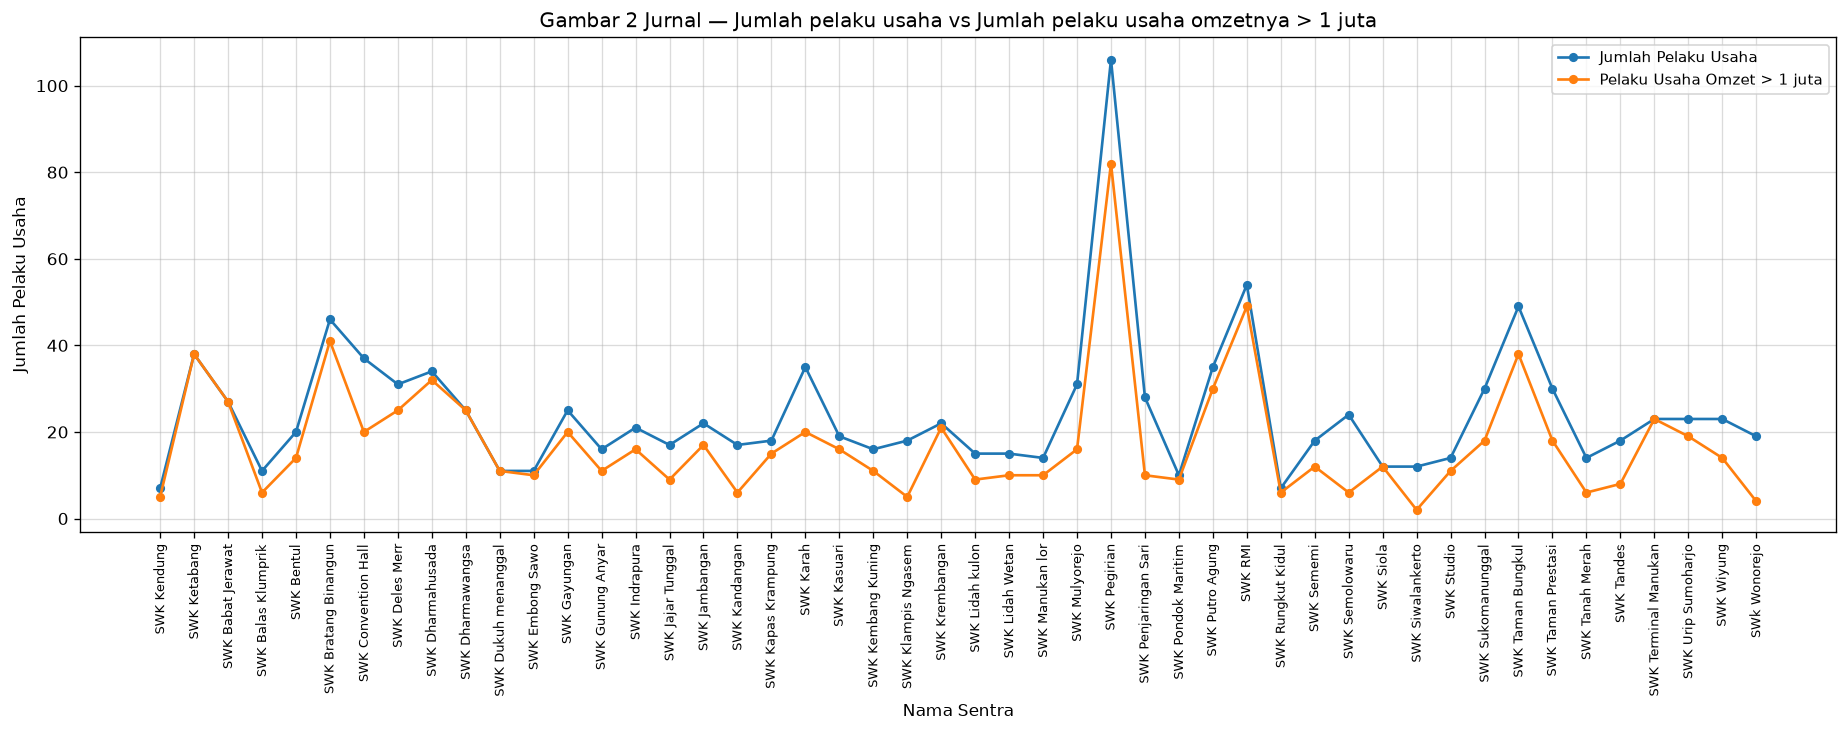

In [3]:
# Statistika Deskriptif Variabel Numerik 48 SWK
num_cols = ['Kapasitas', 'Jumlah pelaku usaha', 'Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah']
display(df_raw[num_cols].describe().round(2))

# GAMBAR 2 JURNAL (Halaman 4): Grafik Garis Perbandingan Pelaku Usaha vs Omzet > 1 Juta (48 Nama Sentra)
x = np.arange(len(df_raw))
fig, ax = plt.subplots(figsize=(15.5, 6.2))
ax.plot(x, df_raw['Jumlah pelaku usaha'], marker='o', markersize=4.5, lw=1.6, color='#1f77b4', label='Jumlah Pelaku Usaha')
ax.plot(x, df_raw['Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah'], marker='o', markersize=4.5, lw=1.6, color='#ff7f0e', label='Pelaku Usaha Omzet > 1 juta')
ax.set_title('Gambar 2 Jurnal — Jumlah pelaku usaha vs Jumlah pelaku usaha omzetnya > 1 juta', fontsize=12)
ax.set_xlabel('Nama Sentra', fontsize=10)
ax.set_ylabel('Jumlah Pelaku Usaha', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(df_raw['Nama sentra'], rotation=90, fontsize=7.5)
ax.grid(True, linestyle='-', alpha=0.45)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

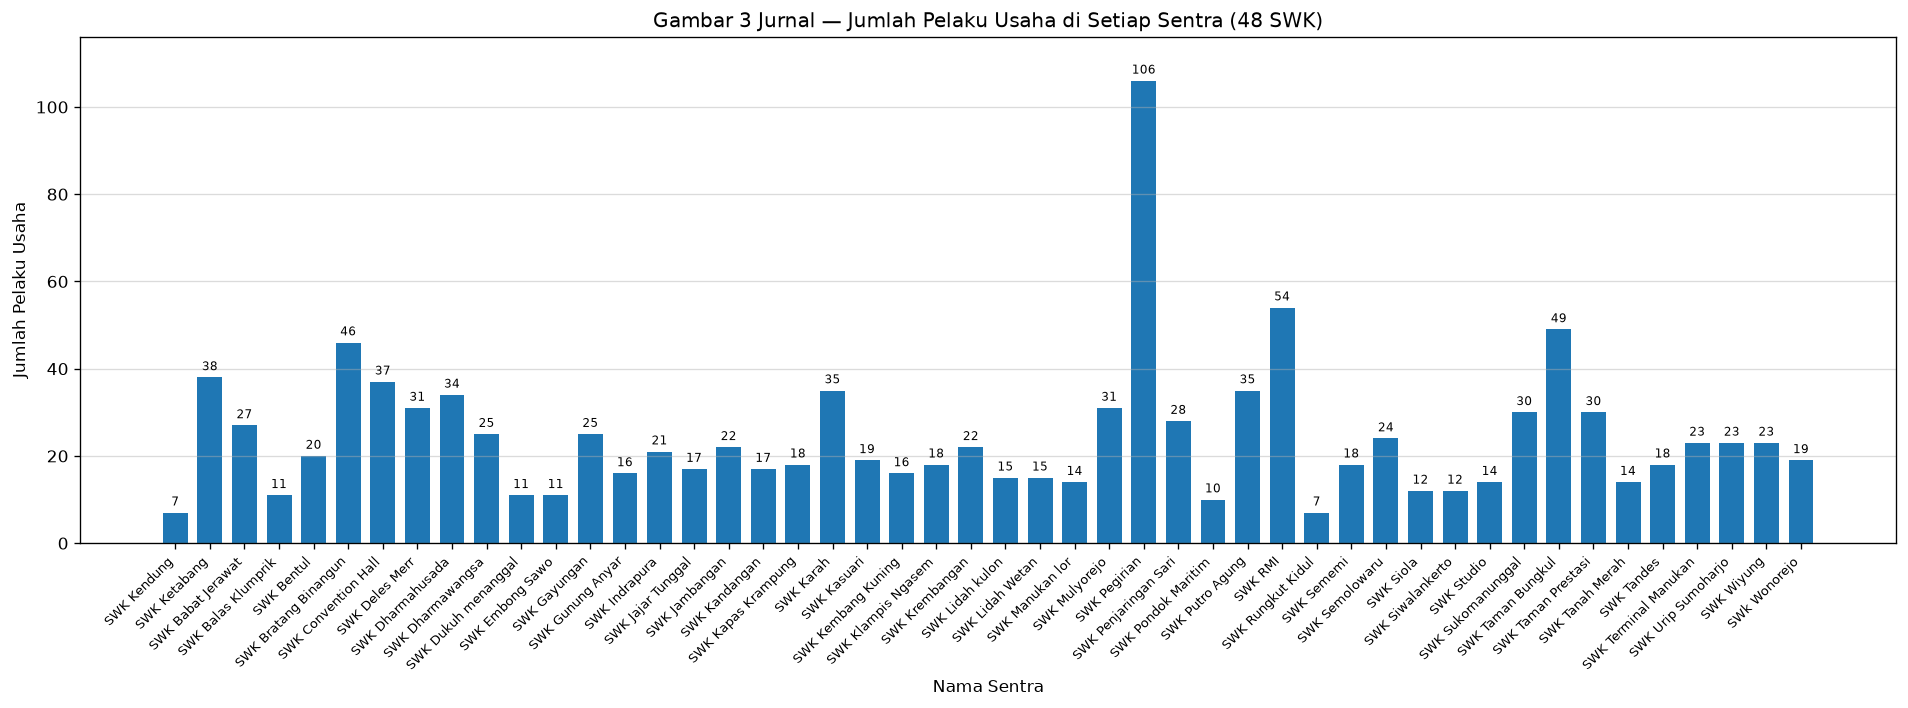

In [4]:
# GAMBAR 3 JURNAL (Halaman 5): Grafik Batang (Histogram) Jumlah Pelaku Usaha di Setiap Sentra (48 SWK + angka)
x = np.arange(len(df_raw))
fig, ax = plt.subplots(figsize=(16.0, 6.0))
bars = ax.bar(x, df_raw['Jumlah pelaku usaha'], color='#1f77b4', width=0.72)
ax.set_title('Gambar 3 Jurnal — Jumlah Pelaku Usaha di Setiap Sentra (48 SWK)', fontsize=12)
ax.set_xlabel('Nama Sentra', fontsize=10)
ax.set_ylabel('Jumlah Pelaku Usaha', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(df_raw['Nama sentra'], rotation=45, ha='right', fontsize=7.5)
ax.set_ylim(0, df_raw['Jumlah pelaku usaha'].max() + 10)
ax.grid(axis='y', linestyle='-', alpha=0.45)
for bar in bars:
    h = int(bar.get_height())
    ax.text(bar.get_x() + bar.get_width() / 2, h + 1.0, str(h), ha='center', va='bottom', fontsize=7.0)
plt.tight_layout()
plt.show()

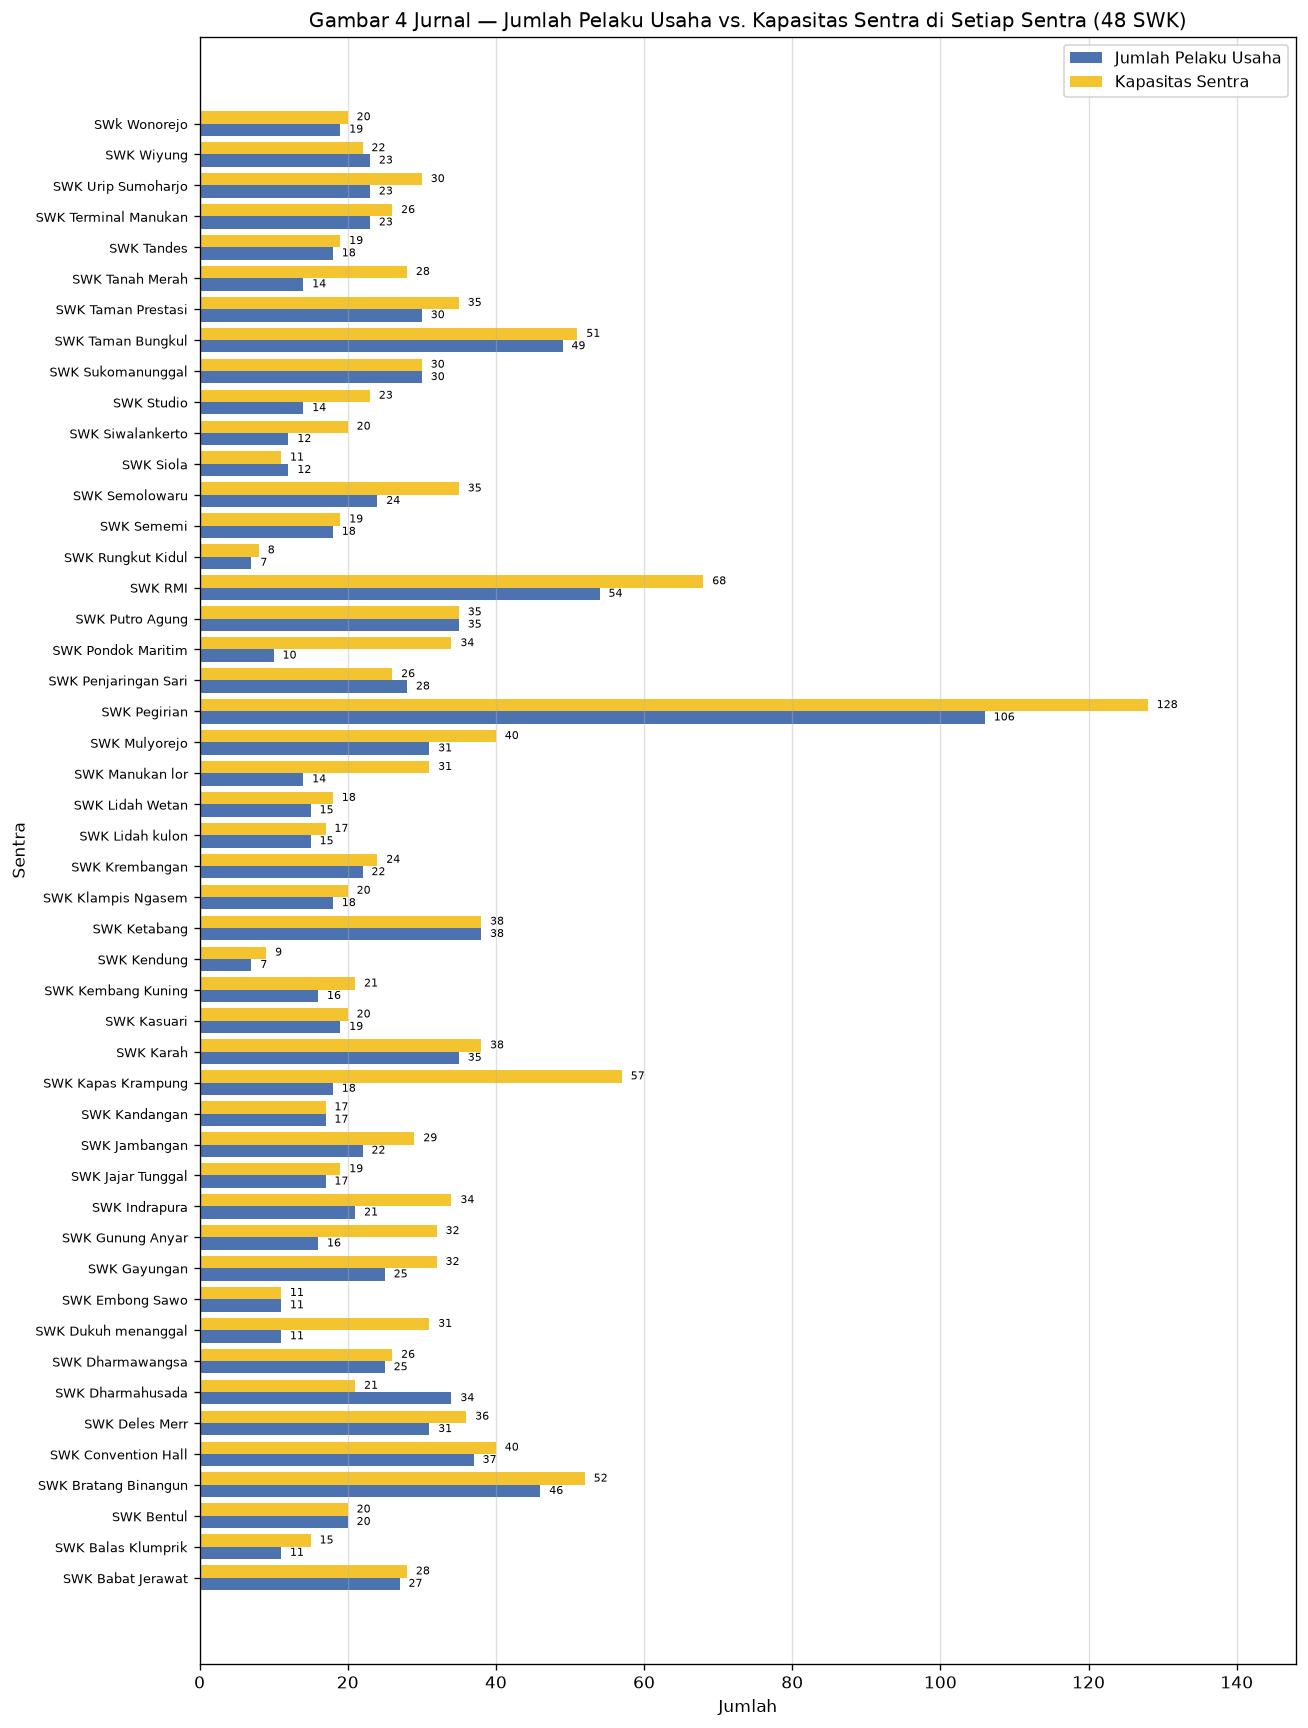

In [5]:
# GAMBAR 4 JURNAL (Halaman 5): Grafik Batang Horizontal Jumlah Pelaku Usaha vs Kapasitas Sentra (48 SWK alfabetis)
df_alpha = df_raw.sort_values('Nama sentra', key=lambda s: s.str.lower()).reset_index(drop=True)
y = np.arange(len(df_alpha))
bar_h = 0.40
fig, ax = plt.subplots(figsize=(11.0, 14.5))
b1 = ax.barh(y - bar_h / 2, df_alpha['Jumlah pelaku usaha'], height=bar_h, color='#4c72b0', label='Jumlah Pelaku Usaha')
b2 = ax.barh(y + bar_h / 2, df_alpha['Kapasitas'], height=bar_h, color='#f4c430', label='Kapasitas Sentra')
ax.set_title('Gambar 4 Jurnal — Jumlah Pelaku Usaha vs. Kapasitas Sentra di Setiap Sentra (48 SWK)', fontsize=12)
ax.set_xlabel('Jumlah', fontsize=10)
ax.set_ylabel('Sentra', fontsize=10)
ax.set_yticks(y)
ax.set_yticklabels(df_alpha['Nama sentra'], fontsize=8.0)
ax.set_xlim(0, df_alpha['Kapasitas'].max() + 20)
ax.grid(axis='x', linestyle='-', alpha=0.4)
ax.legend(loc='upper right', fontsize=9.5)
for bar in b1:
    w = int(bar.get_width())
    ax.text(w + 1.2, bar.get_y() + bar.get_height() / 2, str(w), va='center', ha='left', fontsize=6.8)
for bar in b2:
    w = int(bar.get_width())
    ax.text(w + 1.2, bar.get_y() + bar.get_height() / 2, str(w), va='center', ha='left', fontsize=6.8)
plt.tight_layout()
plt.show()

## Tahap 3 — Pre-processing: Seleksi 4 Variabel, Imputasi Mean (`Tabel 1`), & Normalisasi Z-Score (`Tabel 2`) [Section 4.3.1 Jurnal]

In [6]:
# 3a. Parsing kolom 'Luas sentra' (menghapus 'm2' & konversi koma ke titik) + Seleksi 4 Variabel Utama
def parse_luas_m2(val):
    if pd.isna(val):
        return np.nan
    s = str(val).replace('m2', '').strip()
    return float(s.replace(',', '.')) if s else np.nan

df = df_raw.copy()
df['Luas_Sentra_m2'] = df['Luas sentra'].apply(parse_luas_m2)
feature_cols = [
    'Luas_Sentra_m2',
    'Kapasitas',
    'Jumlah pelaku usaha',
    'Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah',
]
df_feat = df[feature_cols].copy()

# 3b. Deteksi Missing Value & Imputasi Mean (6 baris kosong / hanya 'm2' pada Luas Sentra)
missing_swks = df.loc[df['Luas_Sentra_m2'].isna(), 'Nama sentra'].tolist()
mean_luas = df_feat['Luas_Sentra_m2'].mean()
print(f'Missing Value pada Luas_Sentra_m2 : {len(missing_swks)} SWK -> {missing_swks}')
df_feat['Luas_Sentra_m2'] = df_feat['Luas_Sentra_m2'].fillna(mean_luas)
print(f'Imputasi Mean Luas Sentra         : {mean_luas:.5f} m2')

# TABEL 1 JURNAL (LENGKAP 48 BARIS): Dataset Setelah Cleaning & Imputasi Mean
df_tabel1 = pd.DataFrame({
    'Nama Sentra': df['Nama sentra'],
    'Luas Sentra (m2)': df_feat['Luas_Sentra_m2'].round(5),
    'Kapasitas': df_feat['Kapasitas'].astype(int),
    'Jumlah Pelaku Usaha': df_feat['Jumlah pelaku usaha'].astype(int),
    'Jumlah Pelaku Usaha Omzetnya > 1 juta': df_feat['Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah'].astype(int),
})
df_tabel1.index = np.arange(1, len(df_tabel1) + 1)
df_tabel1.index.name = 'No'
print('\n=== TABEL 1 REPEAT: DATASET 48 SWK SETELAH CLEANING & IMPUTASI MEAN ===')
display(df_tabel1)

# 3c. Normalisasi Z-Score (StandardScaler) -> TABEL 2 JURNAL (LENGKAP 48 BARIS)
X_scaled = StandardScaler().fit_transform(df_feat.values)
df_z = pd.DataFrame(X_scaled, columns=['Luas Sentra (m2)', 'Kapasitas', 'Jumlah Pelaku Usaha', 'Jumlah Pelaku Usaha Omzetnya > 1 juta'])
df_tabel2 = df_z.round(6).copy()
df_tabel2.insert(0, 'Nama Sentra', df['Nama sentra'].values)
df_tabel2.index = np.arange(1, len(df_tabel2) + 1)
df_tabel2.index.name = 'No'
print('\n=== TABEL 2 REPEAT: DATASET 48 SWK SETELAH NORMALISASI Z-SCORE ===')
display(df_tabel2)

Missing Value pada Luas_Sentra_m2 : 6 SWK -> ['SWK Kendung', 'SWK Kasuari', 'SWK Rungkut Kidul', 'SWK Siola', 'SWK Studio', 'SWK Taman Bungkul']
Imputasi Mean Luas Sentra         : 663.87143 m2

=== TABEL 1 REPEAT: DATASET 48 SWK SETELAH CLEANING & IMPUTASI MEAN ===


,Nama Sentra,Luas Sentra (m2),Kapasitas,Jumlah Pelaku Usaha,Jumlah Pelaku Usaha Omzetnya > 1 juta
No,,,,,
1,SWK Kendung,663.87143,9,7,5
2,SWK Ketabang,569.30000,38,38,38
3,SWK Babat Jerawat,1412.00000,28,27,27
4,SWK Balas Klumprik,560.00000,15,11,6
5,SWK Bentul,227.50000,20,20,14
6,SWK Bratang Binangun,2000.00000,52,46,41
7,SWK Convention Hall,960.00000,40,37,20
8,SWK Deles Merr,890.00000,36,31,25
9,SWK Dharmahusada,350.00000,21,34,32



=== TABEL 2 REPEAT: DATASET 48 SWK SETELAH NORMALISASI Z-SCORE ===


,Nama Sentra,Luas Sentra (m2),Kapasitas,Jumlah Pelaku Usaha,Jumlah Pelaku Usaha Omzetnya > 1 juta
No,,,,,
1,SWK Kendung,0.000000,-1.128038,-1.090876,-0.898956
2,SWK Ketabang,-0.252347,0.423571,0.860114,1.462481
3,SWK Babat Jerawat,1.996247,-0.111466,0.167827,0.675335
4,SWK Balas Klumprik,-0.277162,-0.807015,-0.839135,-0.827398
5,SWK Bentul,-1.164379,-0.539496,-0.272719,-0.254928
6,SWK Bratang Binangun,3.565219,1.172624,1.363595,1.677157
7,SWK Convention Hall,0.790166,0.530579,0.797178,0.174424
8,SWK Deles Merr,0.603383,0.316564,0.419568,0.532218
9,SWK Dharmahusada,-0.837510,-0.485992,0.608373,1.033129


## Tahap 4 — Clustering AHC 4 Metode Linkage: Dendrogram (`Gambar 5, 6, 7a, 8`) & Daftar Lengkap Anggota 48 SWK [Section 4.3.2–4.3.5 Jurnal]

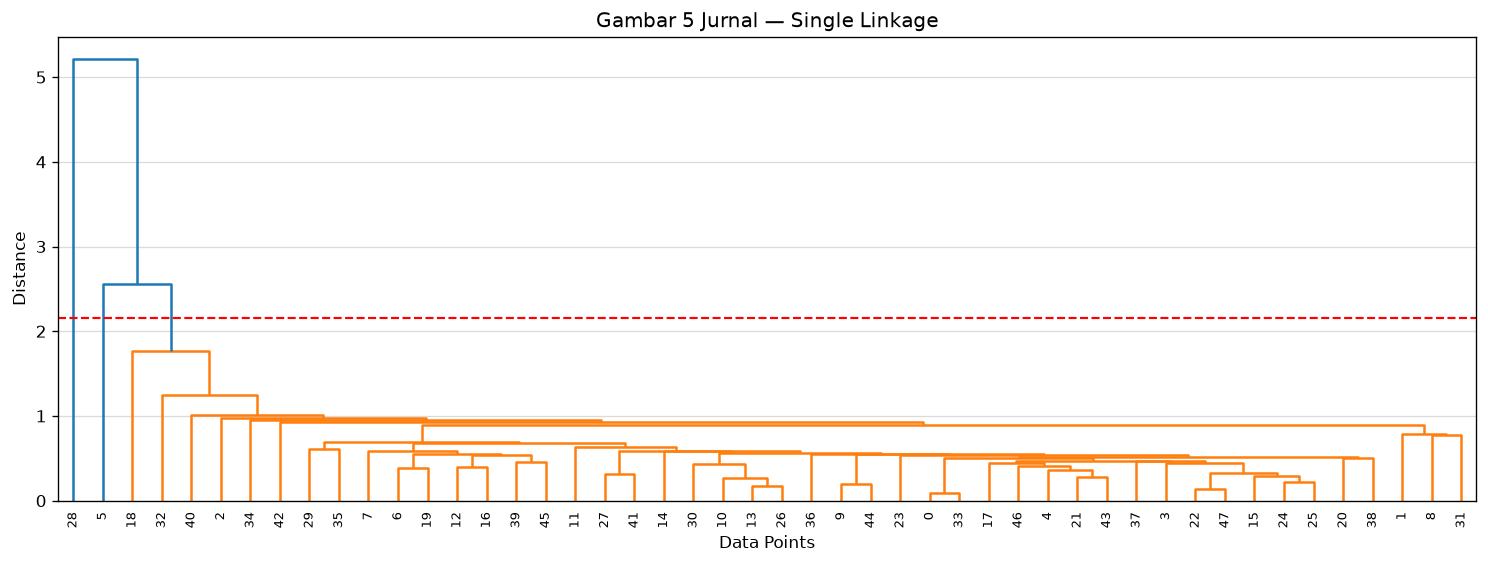

--- Anggota Cluster Single Linkage (Total 48 SWK) ---
Cluster 1 (46 anggota): SWK Kendung, SWK Ketabang, SWK Babat Jerawat, SWK Balas Klumprik, SWK Bentul, SWK Convention Hall, SWK Deles Merr, SWK Dharmahusada, SWK Dharmawangsa, SWK Dukuh menanggal, SWK Embong Sawo, SWK Gayungan, SWK Gunung Anyar, SWK Indrapura, SWK Jajar Tunggal, SWK Jambangan, SWK Kandangan, SWK Kapas Krampung, SWK Karah, SWK Kasuari, SWK Kembang Kuning, SWK Klampis Ngasem, SWK Krembangan, SWK Lidah kulon, SWK Lidah Wetan, SWK Manukan lor, SWK Mulyorejo, SWK Penjaringan Sari, SWK Pondok Maritim, SWK Putro Agung, SWK RMI, SWK Rungkut Kidul, SWK Sememi, SWK Semolowaru, SWK Siola, SWK Siwalankerto, SWK Studio, SWK Sukomanunggal, SWK Taman Bungkul, SWK Taman Prestasi, SWK Tanah Merah, SWK Tandes, SWK Terminal Manukan, SWK Urip Sumoharjo, SWK Wiyung, SWk Wonorejo
Cluster 2 (1 anggota): SWK Bratang Binangun
Cluster 3 (1 anggota): SWK Pegirian



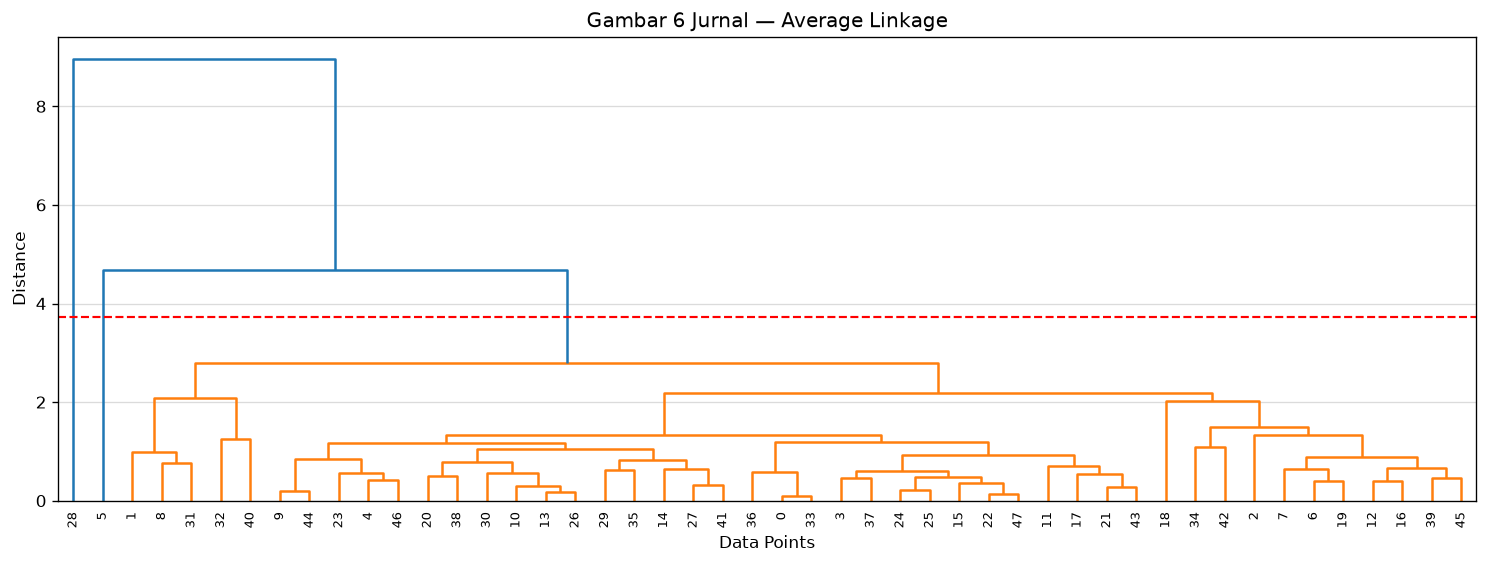

--- Anggota Cluster Average Linkage (Total 48 SWK) ---
Cluster 1 (46 anggota): SWK Kendung, SWK Ketabang, SWK Babat Jerawat, SWK Balas Klumprik, SWK Bentul, SWK Convention Hall, SWK Deles Merr, SWK Dharmahusada, SWK Dharmawangsa, SWK Dukuh menanggal, SWK Embong Sawo, SWK Gayungan, SWK Gunung Anyar, SWK Indrapura, SWK Jajar Tunggal, SWK Jambangan, SWK Kandangan, SWK Kapas Krampung, SWK Karah, SWK Kasuari, SWK Kembang Kuning, SWK Klampis Ngasem, SWK Krembangan, SWK Lidah kulon, SWK Lidah Wetan, SWK Manukan lor, SWK Mulyorejo, SWK Penjaringan Sari, SWK Pondok Maritim, SWK Putro Agung, SWK RMI, SWK Rungkut Kidul, SWK Sememi, SWK Semolowaru, SWK Siola, SWK Siwalankerto, SWK Studio, SWK Sukomanunggal, SWK Taman Bungkul, SWK Taman Prestasi, SWK Tanah Merah, SWK Tandes, SWK Terminal Manukan, SWK Urip Sumoharjo, SWK Wiyung, SWk Wonorejo
Cluster 2 (1 anggota): SWK Bratang Binangun
Cluster 3 (1 anggota): SWK Pegirian



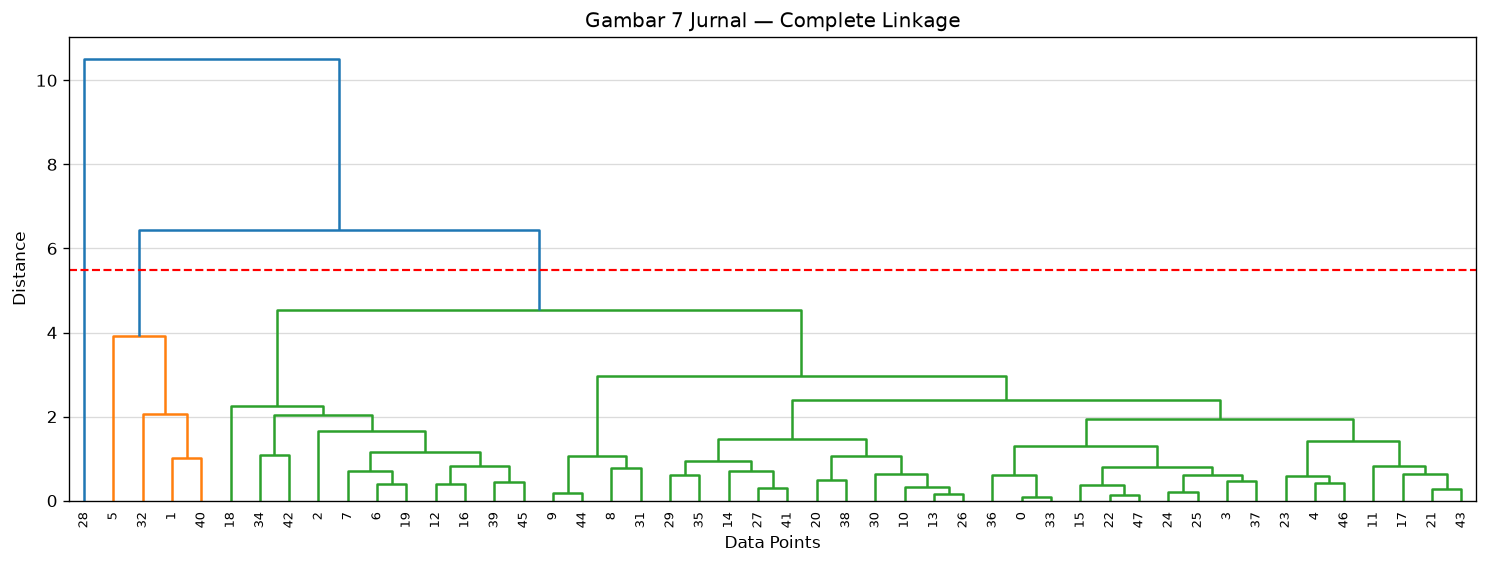

--- Anggota Cluster Complete Linkage (Total 48 SWK) ---
Cluster 1 (4 anggota): SWK Ketabang, SWK Bratang Binangun, SWK RMI, SWK Taman Bungkul
Cluster 2 (43 anggota): SWK Kendung, SWK Babat Jerawat, SWK Balas Klumprik, SWK Bentul, SWK Convention Hall, SWK Deles Merr, SWK Dharmahusada, SWK Dharmawangsa, SWK Dukuh menanggal, SWK Embong Sawo, SWK Gayungan, SWK Gunung Anyar, SWK Indrapura, SWK Jajar Tunggal, SWK Jambangan, SWK Kandangan, SWK Kapas Krampung, SWK Karah, SWK Kasuari, SWK Kembang Kuning, SWK Klampis Ngasem, SWK Krembangan, SWK Lidah kulon, SWK Lidah Wetan, SWK Manukan lor, SWK Mulyorejo, SWK Penjaringan Sari, SWK Pondok Maritim, SWK Putro Agung, SWK Rungkut Kidul, SWK Sememi, SWK Semolowaru, SWK Siola, SWK Siwalankerto, SWK Studio, SWK Sukomanunggal, SWK Taman Prestasi, SWK Tanah Merah, SWK Tandes, SWK Terminal Manukan, SWK Urip Sumoharjo, SWK Wiyung, SWk Wonorejo
Cluster 3 (1 anggota): SWK Pegirian



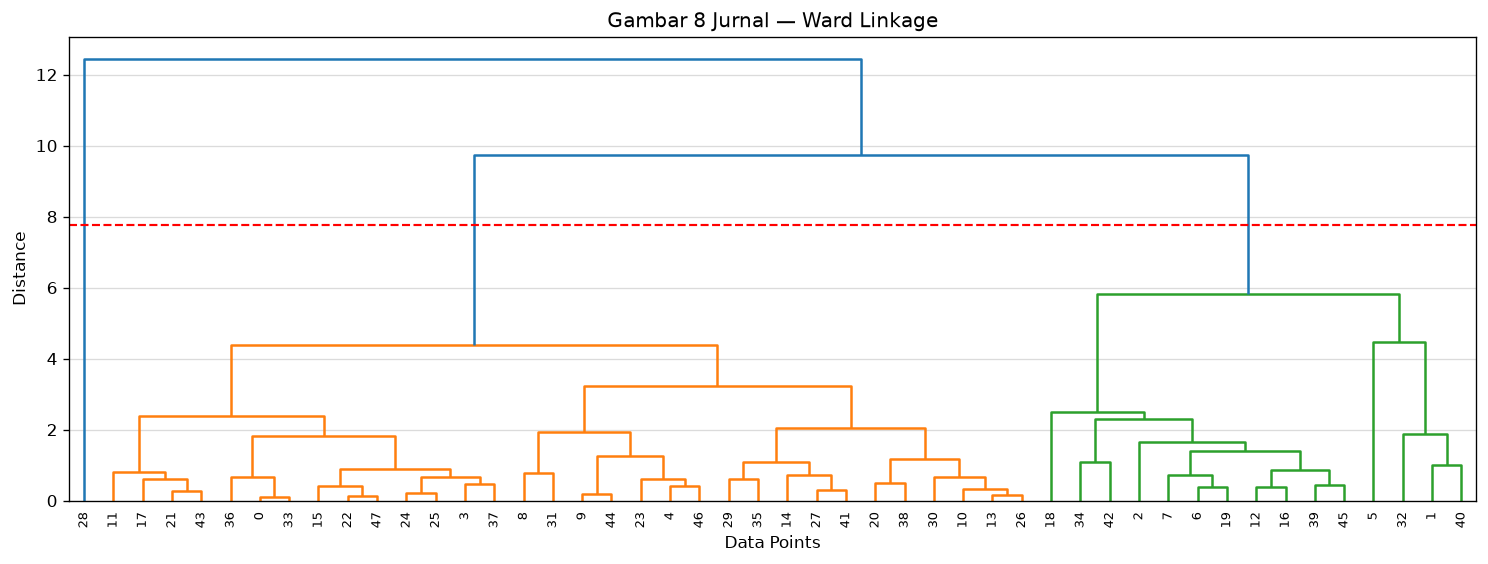

--- Anggota Cluster Ward Linkage (Total 48 SWK) ---
Cluster 1 (32 anggota): SWK Kendung, SWK Balas Klumprik, SWK Bentul, SWK Dharmahusada, SWK Dharmawangsa, SWK Dukuh menanggal, SWK Embong Sawo, SWK Gunung Anyar, SWK Indrapura, SWK Jajar Tunggal, SWK Kandangan, SWK Kasuari, SWK Kembang Kuning, SWK Klampis Ngasem, SWK Krembangan, SWK Lidah kulon, SWK Lidah Wetan, SWK Manukan lor, SWK Mulyorejo, SWK Penjaringan Sari, SWK Pondok Maritim, SWK Putro Agung, SWK Rungkut Kidul, SWK Semolowaru, SWK Siola, SWK Siwalankerto, SWK Studio, SWK Taman Prestasi, SWK Tandes, SWK Terminal Manukan, SWK Wiyung, SWk Wonorejo
Cluster 2 (15 anggota): SWK Ketabang, SWK Babat Jerawat, SWK Bratang Binangun, SWK Convention Hall, SWK Deles Merr, SWK Gayungan, SWK Jambangan, SWK Kapas Krampung, SWK Karah, SWK RMI, SWK Sememi, SWK Sukomanunggal, SWK Taman Bungkul, SWK Tanah Merah, SWK Urip Sumoharjo
Cluster 3 (1 anggota): SWK Pegirian



In [7]:
# Fungsi bantu plot dendrogram persis jurnal (Data Points 0..47 + garis merah putus-putus cut-off k=3)
def plot_journal_dendrogram(Z, title, k=3):
    cut_y = 0.5 * (float(Z[-k, 2]) + float(Z[-(k - 1), 2]))
    fig, ax = plt.subplots(figsize=(12.5, 4.8))
    dendrogram(
        Z, labels=[str(i) for i in range(len(df))],
        leaf_rotation=90, leaf_font_size=7.5,
        color_threshold=cut_y, above_threshold_color='#1f77b4', ax=ax,
    )
    ax.axhline(y=cut_y, color='red', linestyle='--', linewidth=1.3)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Data Points', fontsize=10)
    ax.set_ylabel('Distance', fontsize=10)
    ax.grid(axis='y', linestyle='-', alpha=0.45)
    plt.tight_layout()
    plt.show()

def print_cluster_members(method_label, labels):
    # Urutkan label agar sesuai penomoran jurnal (Pegirian = Cluster 3)
    pegirian_raw = int(labels[df['Nama sentra'] == 'SWK Pegirian'][0])
    other_raws = [int(c) for c in pd.Series(labels).value_counts().index if int(c) != pegirian_raw]
    if method_label == 'Complete Linkage':
        c_4 = [c for c in other_raws if int((labels == c).sum()) == 4][0]
        c_43 = [c for c in other_raws if c != c_4][0]
        cmap = {c_4: 1, c_43: 2, pegirian_raw: 3}
    else:
        other_sorted = sorted(other_raws, key=lambda c: -int((labels == c).sum()))
        cmap = {other_sorted[0]: 1, other_sorted[1]: 2, pegirian_raw: 3}
    mapped = np.array([cmap[int(c)] for c in labels])
    print(f'--- Anggota Cluster {method_label} (Total 48 SWK) ---')
    for cid in [1, 2, 3]:
        members = df.loc[mapped == cid, 'Nama sentra'].tolist()
        print(f'Cluster {cid} ({len(members)} anggota): ' + ', '.join(members))
    print()
    return mapped

D = pdist(X_scaled, metric='euclidean')
Z_dict, mapped_dict = {}, {}
meta_methods = [
    ('single',   'Gambar 5 Jurnal — Single Linkage'),
    ('average',  'Gambar 6 Jurnal — Average Linkage'),
    ('complete', 'Gambar 7 Jurnal — Complete Linkage'),
    ('ward',     'Gambar 8 Jurnal — Ward Linkage'),
]
for method, title in meta_methods:
    Z = linkage(X_scaled, method=method)
    lbl = fcluster(Z, t=3, criterion='maxclust')
    Z_dict[method] = Z
    plot_journal_dendrogram(Z, title, k=3)
    mapped_dict[method] = print_cluster_members(f'{method.title()} Linkage', lbl)

## Tahap 5 — Penentuan Algoritma Optimal (`Tabel 3`) & Validasi Jumlah Cluster (`Grafik Silhouette Score k=2..10`) [Section 4.3.6–4.3.7 Jurnal]

=== TABEL 3 REPEAT vs JURNAL UTAMA (PENENTUAN ALGORITMA OPTIMAL) ===


,Algoritma,Paper_Cophenetic,Repeat_Cophenetic,Paper_Silhouette,Repeat_Silhouette,Selisih_Silhouette,Paper_Proporsi (C1/C2/C3),Repeat_Proporsi (C1/C2/C3)
0,Single Linkage,0.9111,0.9118,0.5461,0.5547,0.0086,46 / 1 / 1,46 / 1 / 1
1,Average Linkage,0.9317,0.9242,0.5461,0.5547,0.0086,46 / 1 / 1,46 / 1 / 1
2,Complete Linkage,0.8734,0.8566,0.4864,0.4893,0.0029,4 / 43 / 1,4 / 43 / 1
3,Ward Linkage,0.6368,0.6295,0.3954,0.3946,-0.0008,31 / 16 / 1,32 / 15 / 1


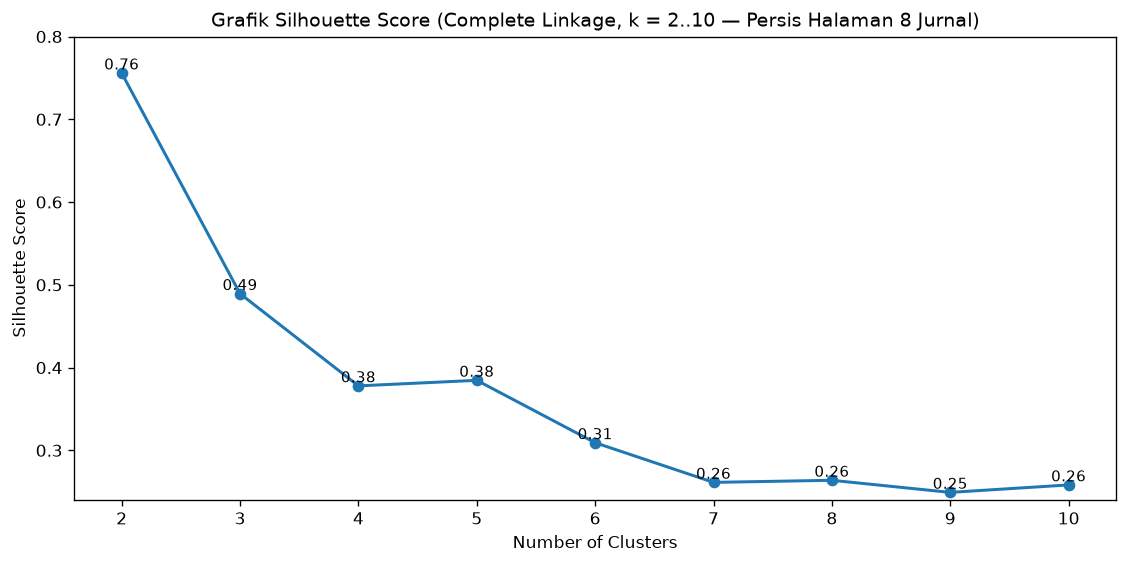

In [8]:
# TABEL 3 JURNAL: Perbandingan Korelasi Cophenetic, Silhouette Coefficient, & Proporsi Cluster 4 Algoritma
paper_table3 = {
    'single':   {'cophenetic': 0.9111, 'silhouette': 0.5461, 'proporsi': '46 / 1 / 1'},
    'average':  {'cophenetic': 0.9317, 'silhouette': 0.5461, 'proporsi': '46 / 1 / 1'},
    'complete': {'cophenetic': 0.8734, 'silhouette': 0.4864, 'proporsi': '4 / 43 / 1'},
    'ward':     {'cophenetic': 0.6368, 'silhouette': 0.3954, 'proporsi': '31 / 16 / 1'},
}
rows_t3 = []
for method in ['single', 'average', 'complete', 'ward']:
    Z = Z_dict[method]
    coph, _ = cophenet(Z, D)
    lbl = mapped_dict[method]
    sil = silhouette_score(X_scaled, lbl)
    cnts = [int((lbl == cid).sum()) for cid in [1, 2, 3]]
    ref = paper_table3[method]
    rows_t3.append({
        'Algoritma': f'{method.title()} Linkage',
        'Paper_Cophenetic': ref['cophenetic'],
        'Repeat_Cophenetic': round(float(coph), 4),
        'Paper_Silhouette': ref['silhouette'],
        'Repeat_Silhouette': round(float(sil), 4),
        'Selisih_Silhouette': round(float(sil) - ref['silhouette'], 4),
        'Paper_Proporsi (C1/C2/C3)': ref['proporsi'],
        'Repeat_Proporsi (C1/C2/C3)': ' / '.join(str(c) for c in cnts),
    })
df_table3 = pd.DataFrame(rows_t3)
print('=== TABEL 3 REPEAT vs JURNAL UTAMA (PENENTUAN ALGORITMA OPTIMAL) ===')
display(df_table3)

# GAMBAR 7 (Halaman 8 Jurnal): Grafik Silhouette Score Complete Linkage untuk k = 2 sampai 10
Z_complete = Z_dict['complete']
ks = list(range(2, 11))
sil_vals = [round(float(silhouette_score(X_scaled, fcluster(Z_complete, t=k, criterion='maxclust'))), 4) for k in ks]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(ks, sil_vals, marker='o', markersize=6, lw=1.8, color='#1f77b4')
ax.set_title('Grafik Silhouette Score (Complete Linkage, k = 2..10 — Persis Halaman 8 Jurnal)', fontsize=11.5)
ax.set_xlabel('Number of Clusters', fontsize=10)
ax.set_ylabel('Silhouette Score', fontsize=10)
ax.set_xticks(ks)
ax.set_ylim(0.24, 0.80)
for k, v in zip(ks, sil_vals):
    ax.text(k, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9.0)
plt.tight_layout()
plt.show()

## Tahap 6 — Interpretasi Cluster (`Tabel 4`), Hasil Lengkap 48 SWK Terklaster, & Strategi Optimalisasi Omzet [Section 4.4 & 5 Jurnal]

In [9]:
# TABEL 4 JURNAL: Rata-Rata Nilai Z-Score 3 Cluster Terbentuk (Complete Linkage)
df['Cluster_AHC'] = mapped_dict['complete']
df_z['Cluster_AHC'] = df['Cluster_AHC']
df_table4 = df_z.groupby('Cluster_AHC').mean().T.round(6)
df_table4.columns = [f'Cluster {c}' for c in df_table4.columns]
df_table4.loc['Rata-Rata'] = df_table4.mean(axis=0).round(6)
print('=== TABEL 4 REPEAT: RATA-RATA CLUSTER TERBENTUK (COCOK 6 DESIMAL DENGAN JURNAL) ===')
display(df_table4)

# Profil Nilai Asli & Strategi Optimalisasi Omzet per Cluster
profil_asli = df.groupby('Cluster_AHC').agg(
    Jumlah_SWK=('Nama sentra', 'count'),
    Rata_Luas_m2=('Luas_Sentra_m2', lambda s: round(float(df_feat.loc[s.index, 'Luas_Sentra_m2'].mean()), 2)),
    Rata_Kapasitas=('Kapasitas', 'mean'),
    Rata_Pelaku_Usaha=('Jumlah pelaku usaha', 'mean'),
    Rata_Omzet_gt_1Jt=('Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah', 'mean'),
).round(2)
profil_asli['Interpretasi_&_Strategi'] = [
    'Cluster 1 (4 SWK Berkembang Baik): Stabilitas & aktivitas tinggi -> pengembangan berkelanjutan & inovasi digital',
    'Cluster 2 (43 SWK Kurang Berkembang): Semua variabel di bawah rata-rata -> prioritas infrastruktur, pelatihan & promosi',
    'Cluster 3 (1 SWK Sangat Sukses — SWK Pegirian): Kapasitas & omzet tertinggi -> ekspansi, diversifikasi & model percontohan',
]
display(profil_asli)

# Tabel Lengkap Hasil Pengelompokan Seluruh 48 SWK Surabaya
df_hasil_48 = df_tabel1.copy()
df_hasil_48.insert(1, 'Kecamatan', df['Kecamatan'].values)
df_hasil_48['Cluster_AHC'] = df['Cluster_AHC'].values
df_hasil_48['Kategori'] = df_hasil_48['Cluster_AHC'].map({1: 'Berkembang Baik (4 SWK)', 2: 'Kurang Berkembang (43 SWK)', 3: 'Sangat Sukses (1 SWK)'})
print('\n=== HASIL AKHIR SEGMENTASI LENGKAP 48 SWK SURABAYA (COMPLETE LINKAGE k = 3) ===')
display(df_hasil_48)

=== TABEL 4 REPEAT: RATA-RATA CLUSTER TERBENTUK (COCOK 6 DESIMAL DENGAN JURNAL) ===


,Cluster 1,Cluster 2,Cluster 3
Luas Sentra (m2),0.825636,-0.093988,0.738934
Kapasitas,1.186000,-0.232161,5.238910
Jumlah Pelaku Usaha,1.410796,-0.250765,5.139703
Jumlah Pelaku Usaha Omzetnya > 1 juta,1.712937,-0.266577,4.611064
Rata-Rata,1.283842,-0.210873,3.932153


,Jumlah_SWK,Rata_Luas_m2,Rata_Kapasitas,Rata_Pelaku_Usaha,Rata_Omzet_gt_1Jt,Interpretasi_&_Strategi
Cluster_AHC,,,,,,
1,4,973.29,52.25,46.75,41.50,Cluster 1 (4 SWK Berkembang Baik): Stabilitas ...
2,43,628.65,25.74,20.35,13.84,Cluster 2 (43 SWK Kurang Berkembang): Semua va...
3,1,940.80,128.00,106.00,82.00,Cluster 3 (1 SWK Sangat Sukses — SWK Pegirian)...



=== HASIL AKHIR SEGMENTASI LENGKAP 48 SWK SURABAYA (COMPLETE LINKAGE k = 3) ===


,Nama Sentra,Kecamatan,Luas Sentra (m2),Kapasitas,Jumlah Pelaku Usaha,Jumlah Pelaku Usaha Omzetnya > 1 juta,Cluster_AHC,Kategori
No,,,,,,,,
1,SWK Kendung,BENOWO,663.87143,9,7,5,2,Kurang Berkembang (43 SWK)
2,SWK Ketabang,GENTENG,569.30000,38,38,38,1,Berkembang Baik (4 SWK)
3,SWK Babat Jerawat,PAKAL,1412.00000,28,27,27,2,Kurang Berkembang (43 SWK)
4,SWK Balas Klumprik,WIYUNG,560.00000,15,11,6,2,Kurang Berkembang (43 SWK)
5,SWK Bentul,WONOKROMO,227.50000,20,20,14,2,Kurang Berkembang (43 SWK)
6,SWK Bratang Binangun,GUBENG,2000.00000,52,46,41,1,Berkembang Baik (4 SWK)
7,SWK Convention Hall,SUKOLILO,960.00000,40,37,20,2,Kurang Berkembang (43 SWK)
8,SWK Deles Merr,SUKOLILO,890.00000,36,31,25,2,Kurang Berkembang (43 SWK)
9,SWK Dharmahusada,GUBENG,350.00000,21,34,32,2,Kurang Berkembang (43 SWK)
